In [284]:
# %pip  install numpy pandas matplotlib seaborn joblib DataProfiler scikit-learn

#### Étape 1 — Chargement et Analyse exploratoire des données

- comprendre la structure générale du jeu de données (types de données, dimensions, aperçus) ;
- Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes. 
- Produire des statistiques descriptives.
- Étudier la distribution de la variable cible et l’éventuel déséquilibre des classes.
- Analyser les relations entre les variables explicatives et la cible.
- Examiner les corrélations entre les variables.
- identifier les variables les plus fortement liées au niveau de risque ;

In [285]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [286]:
df = pd.read_csv('../data/raw/dataset.csv')

In [287]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [288]:
df.tail()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


In [289]:
df.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [290]:
df.ndim

2

In [291]:
df.shape

(2000, 17)

In [292]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

##### Observation : La distribution des données est symetrique et suit la loi normal, car la moyenne egal appriximativement à la mediane.

In [ ]:
df.describe().T
#histograme

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


##### Nous Observant que il ya des valeurs manqauntes dans ,Sleep_Hours, GPA, Social_Media_Hours, Financial_Stress, Family_Support, Attendance_Rate
##### => Comme decision  : Imputer les valeurs numériques par la median, et les valeurs catégoriels par la valeur la plus fréquence.

In [294]:
df.isna().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

##### Nous observant que il n'y a pas de lignes dupliqués

In [295]:
df.duplicated().sum()

np.int64(0)

In [296]:
df.describe(include="object")

C:\Users\Youcode\AppData\Local\Temp\ipykernel_20576\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


##### Nous observant que il ya une positive correlation entre Year_of_Study et Study_Hours_per_Week, et aussi entre Screen_time_Hours et Social_Media_Hours, et entre GPA et Study_Hours_per_Week.
#### Nous observant que il ya une negative correlation etre Stuy_Hours_per_Week et Social_Media_Hours, et aussi entre Stuy_Hours_per_Week et Screen_time_Hours.

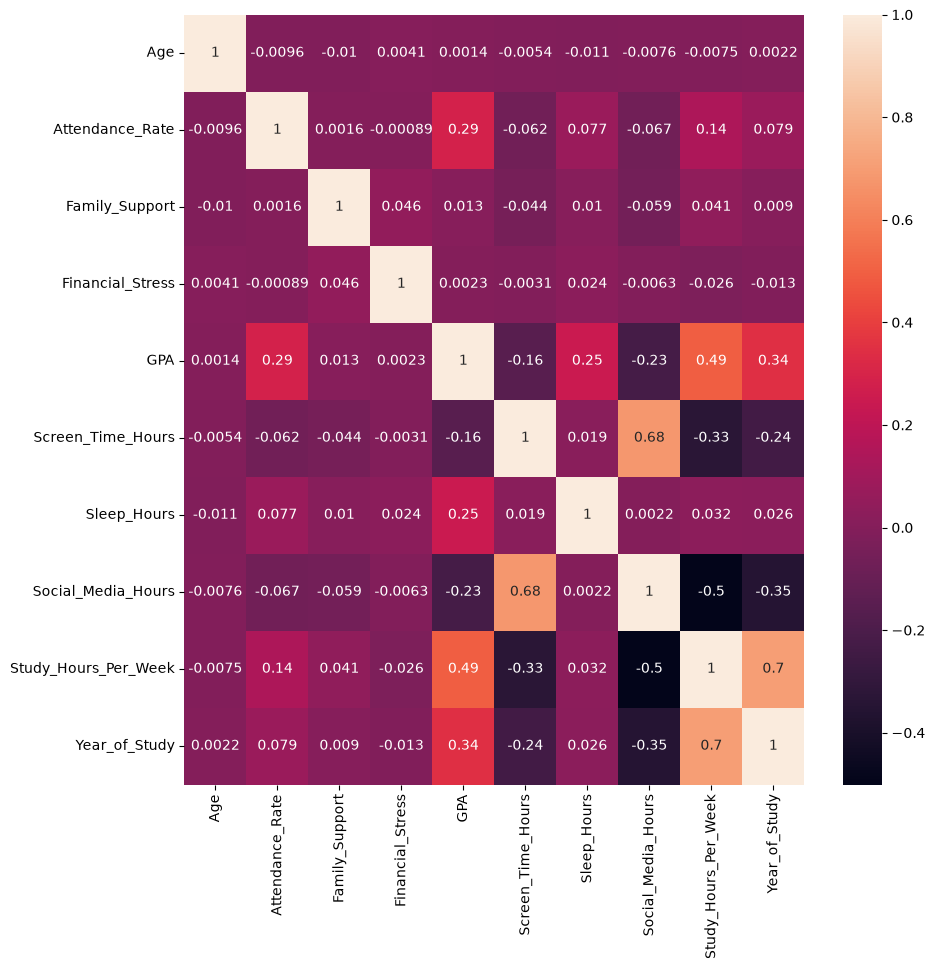

In [297]:
data = df.columns.difference(['Mental_Health_Risk', 'Previous_Mental_Health_History', 'Diet_Quality', 'Part_Time_Job', 'Physical_Activity', 'Gender', 'Student_ID'])
plt.figure(figsize=(10, 10))
sns.heatmap(df[data].corr(), annot=True)
plt.show()

##### Description des colonnes

- GPA : (moyenne pondérée cumulative) la moyenne de tout les points de notes obtenus par un étudiant sur l'ensemble de ses cours, pondérée par le nombre de credits(heures) de chaque matiére.
- Studiant_ID : Identifiant Unique d'un étudiant.
- Age : Age d'un etudiant en années
- Gender : Sexe de l'étudiant(Female, Male, Non-binary)
- Year_of_Study : Année académique actuelle.
- Sleep_Hours : Moyenne d'heures de dormir en nuie
- Study_Hours_Per_Week : Heure d'études par semaine.
- Social_Media_Hours : Moyenne d'heurs d'usage du social media quotidienement.
Screen_Time_Hours : Total d'heure du screen quotidienement.
- Physical_Activity : Frequence des exercices par weekend.
- Financial_Stress : Stress financier ressenti.
- FamilySupport : Score de support de la famille.
- Attendance_Rate : pourcentage de présence.
- Part_Time_Job : emploi à temps partiel or travail à temps partiel.
- Die_Quality : L'auto-evaluation de la qualité du régime alimentaire.
- Previous_Mental_Health_History : Maladie mental diagnistiquée anterieurement.
- Mental_Health_Risk : level de risk prédicté.

##### Nous obsetvant que il ya des valeurs abérants pour Age, Attendance_Rate, Family_Support, Finance_Stress, GPA, Screen_Time_Hours, Sleep_Hours, Social_Media_Hours, Study_Hours_Per_Week
##### => Comme Decision utilisaiton de IQR     

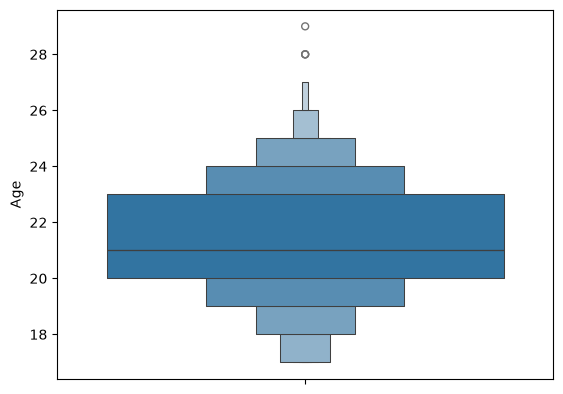

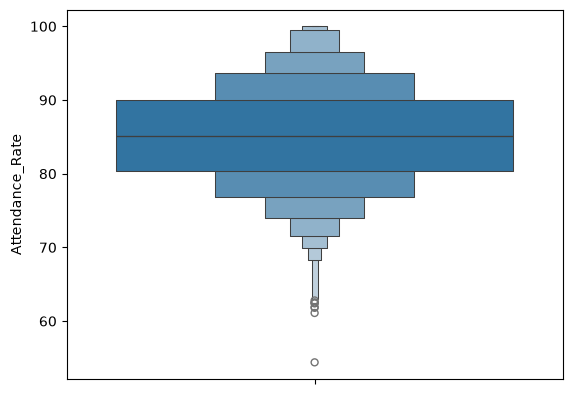

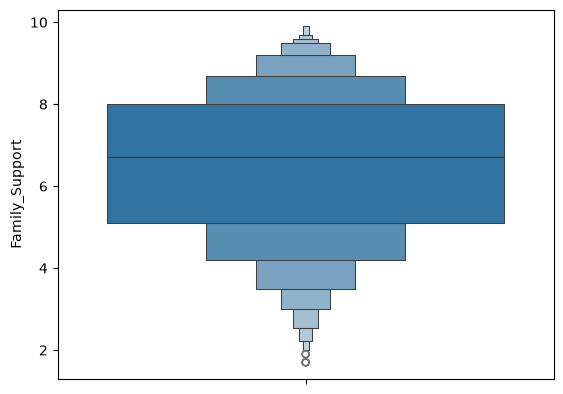

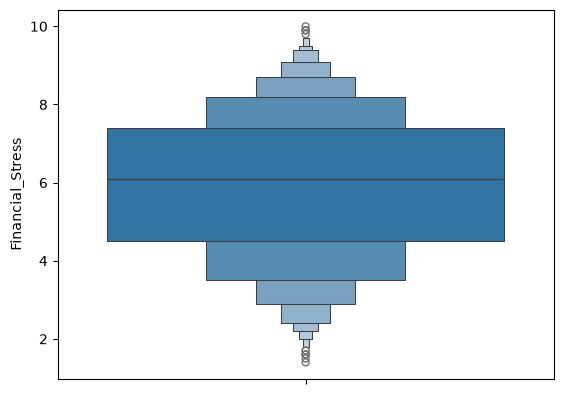

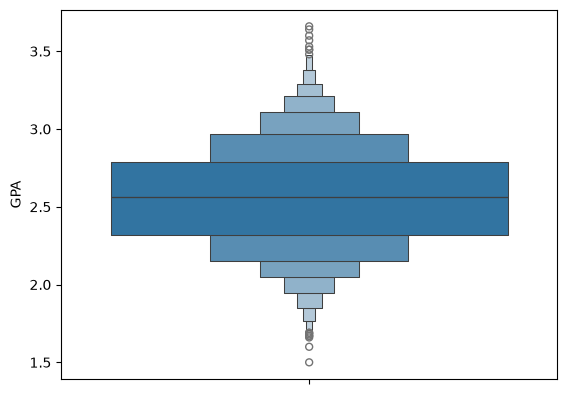

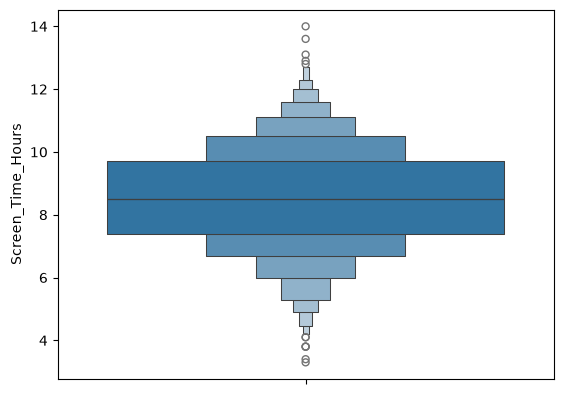

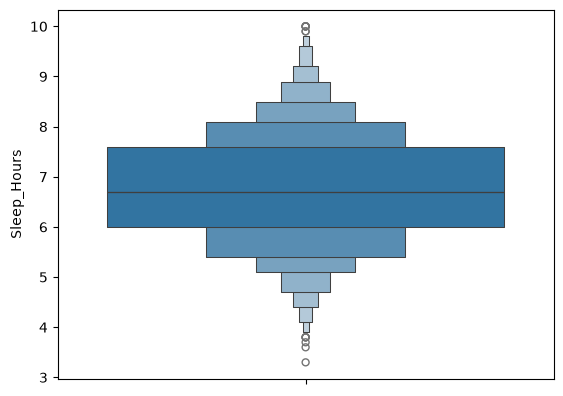

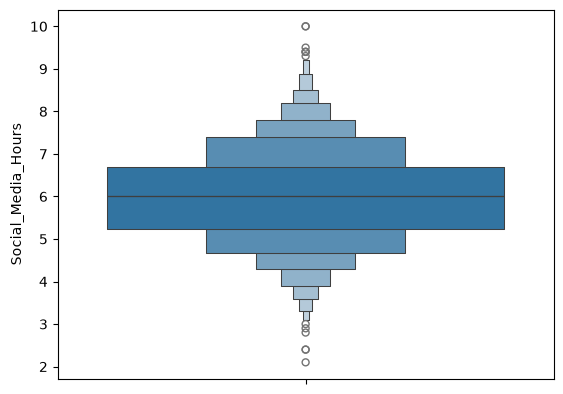

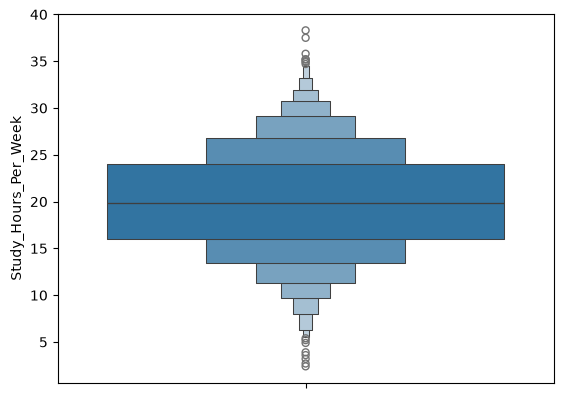

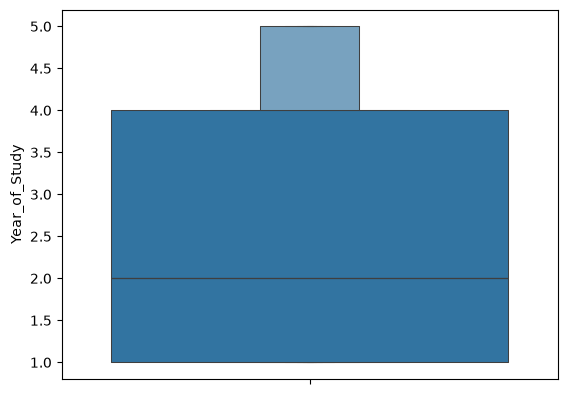

In [ ]:
for col in data:
      sns.boxenplot(df[col])
      plt.show()
      # averifier

#### Visualisaiton de La distribution des variables continues

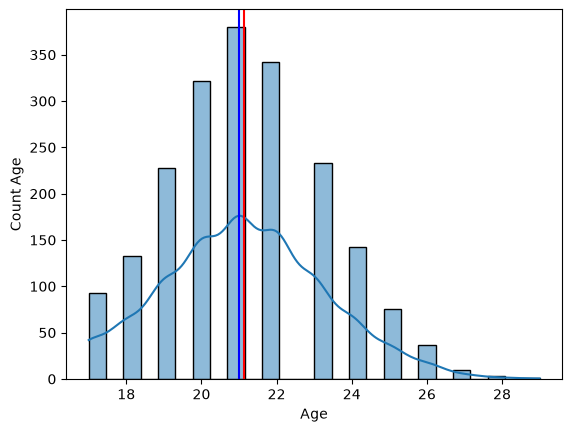

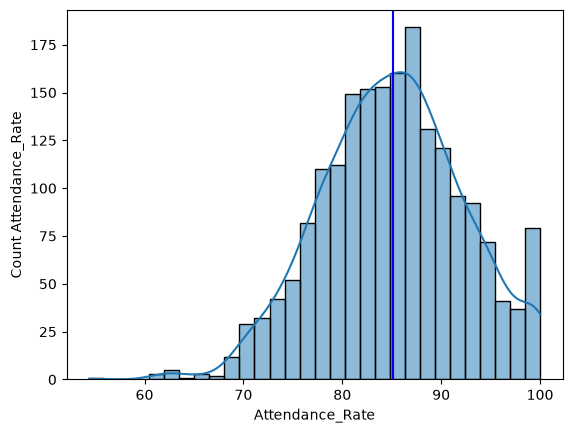

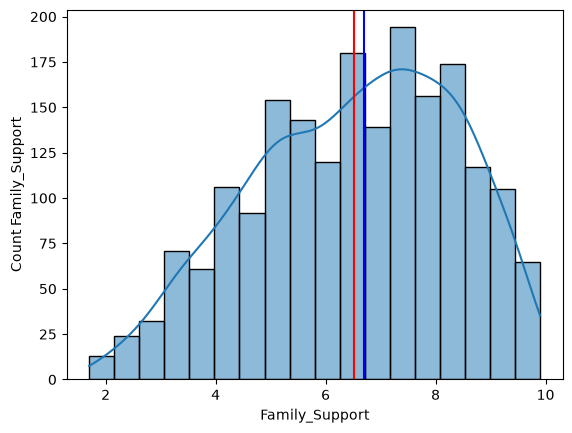

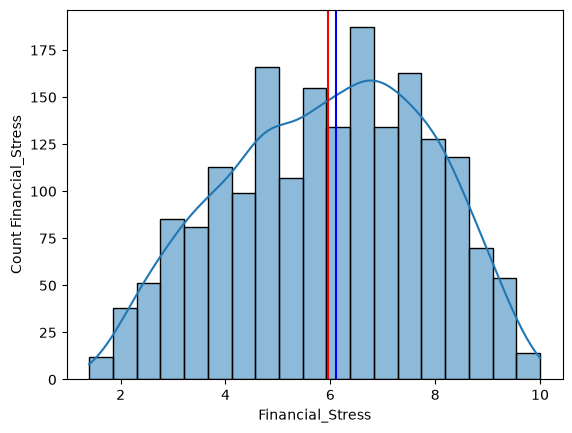

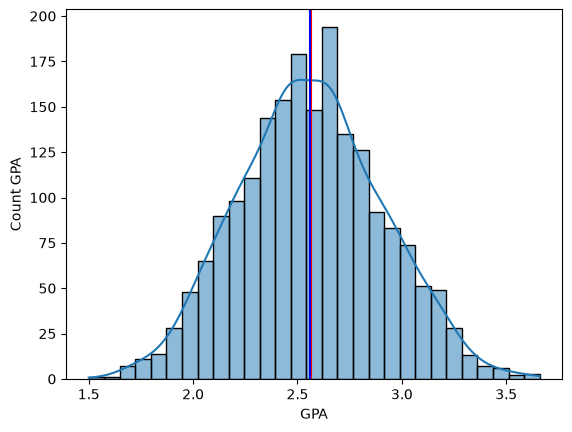

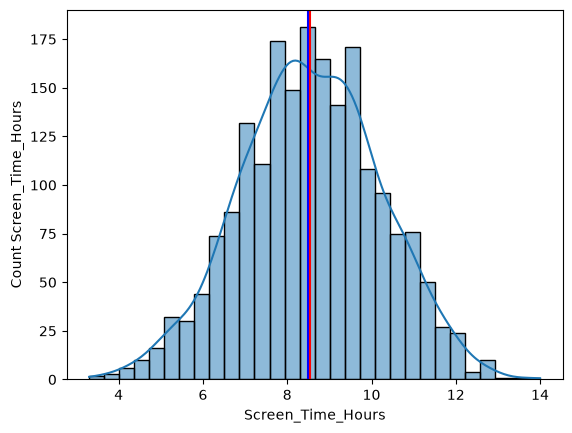

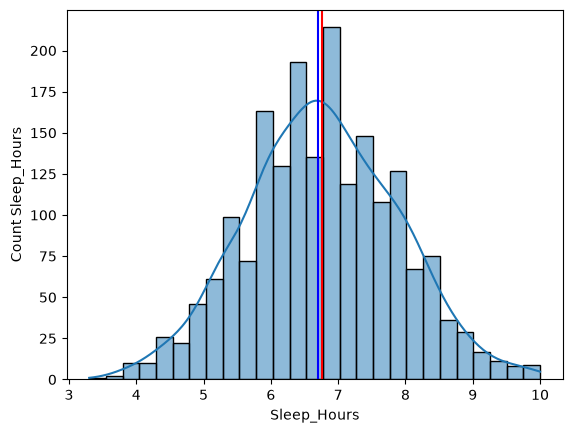

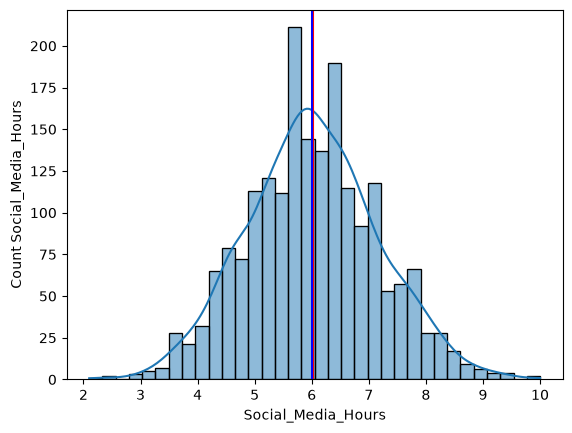

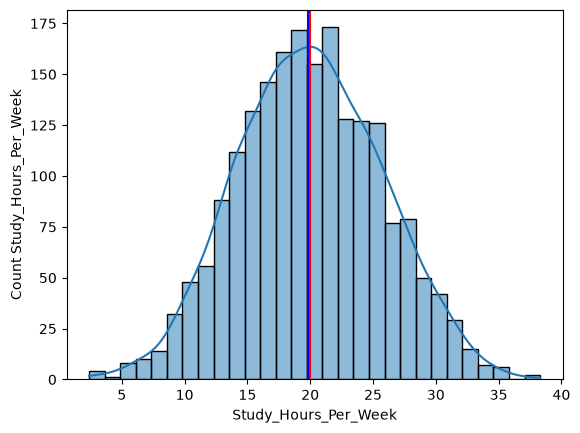

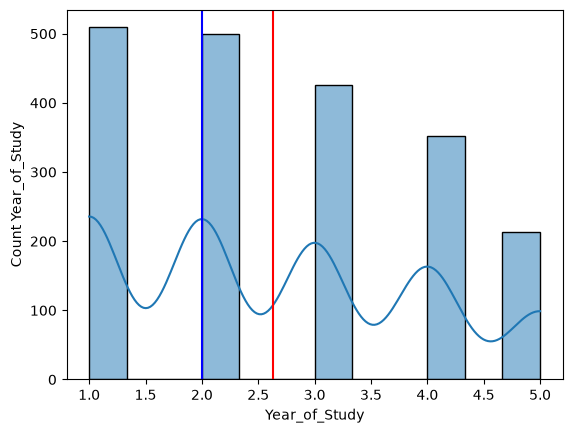

In [299]:
for col in data:
      sns.histplot(df[col], kde=True)
      plt.axvline(df[col].mean(), c='r')
      plt.axvline(df[col].median(), c='b')
      plt.xlabel(col)
      plt.ylabel(f"Count {col}")
      plt.show()


In [300]:
target = 'Mental_Health_Risk'
counts = df[target].value_counts()
pourcentages = df[target].value_counts(normalize=True) * 100


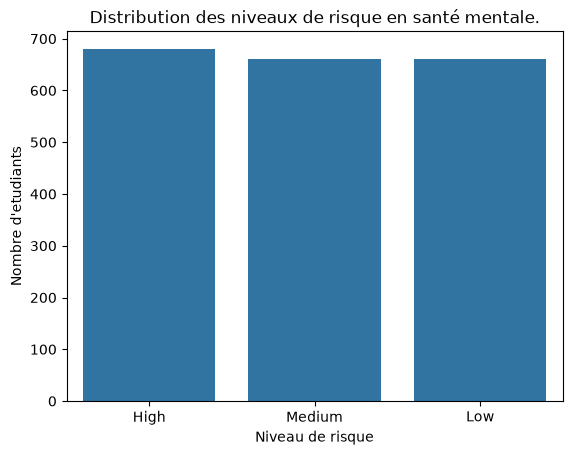

In [301]:
sns.countplot(data=df, x=target, order=counts.index)
plt.title('Distribution des niveaux de risque en santé mentale.')
plt.xlabel('Niveau de risque')
plt.ylabel("Nombre d'etudiants")
plt.show()

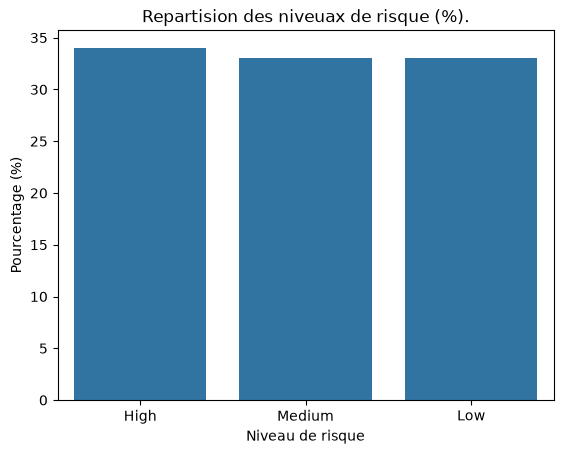

In [302]:
sns.barplot(x=pourcentages.index, y=pourcentages.values)
plt.title('Repartision des niveuax de risque (%).')
plt.xlabel('Niveau de risque')
plt.ylabel("Pourcentage (%)")
plt.show()

#### Rapport entre la classe majoritaire et minoritaire

In [ ]:
imbalenced_ratio = counts.max() / counts.min()
print(f'Imbalenced ratio : {imbalenced_ratio:.2f}')
# La classe majoritaire contient une fois plus d'observations que la classe minoritaire.
# verofiocation d'interp

Imbalenced ratio : 1.03


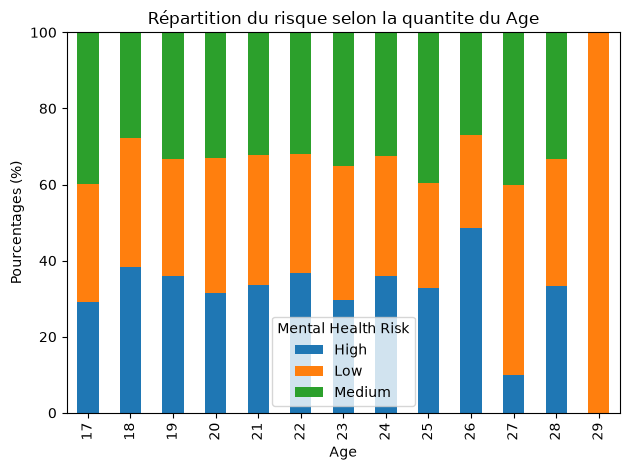

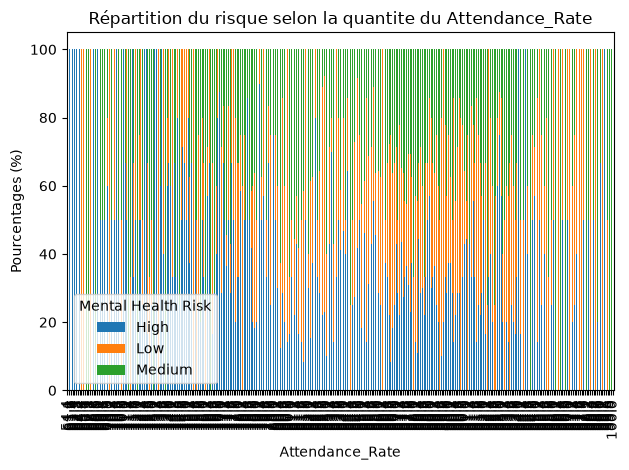

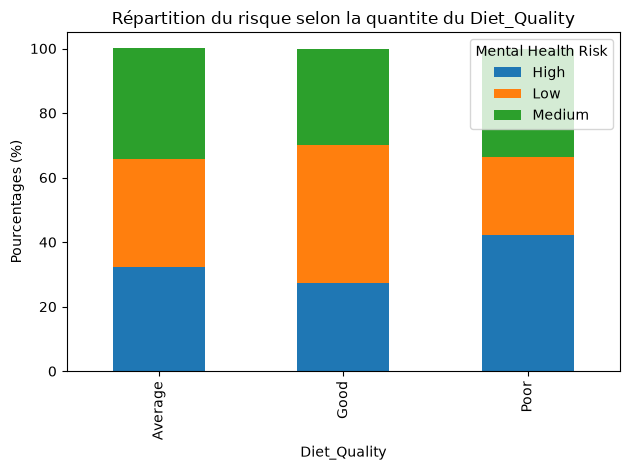

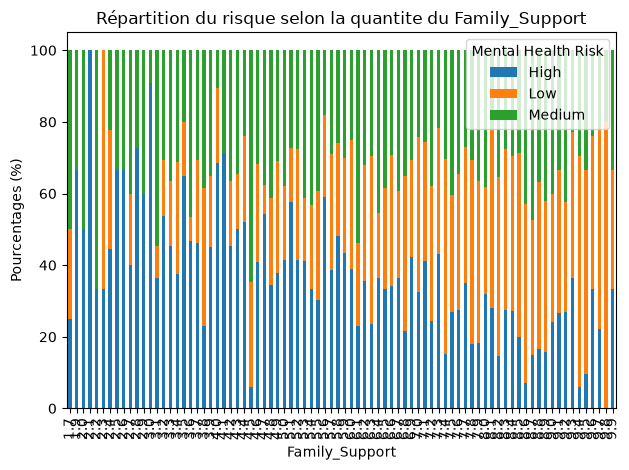

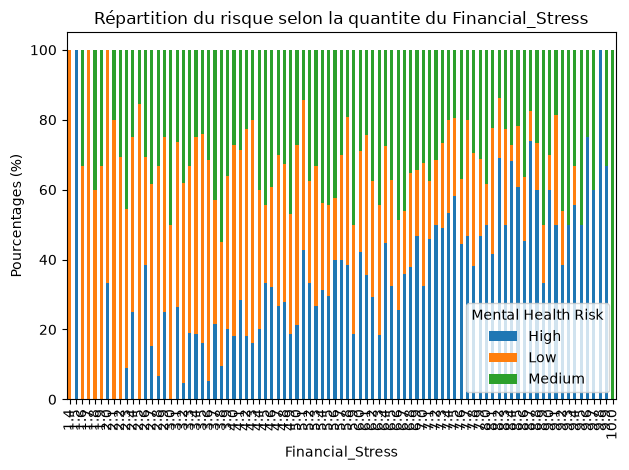

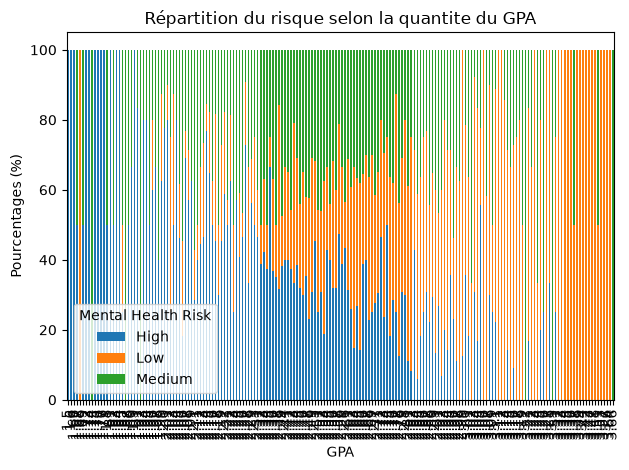

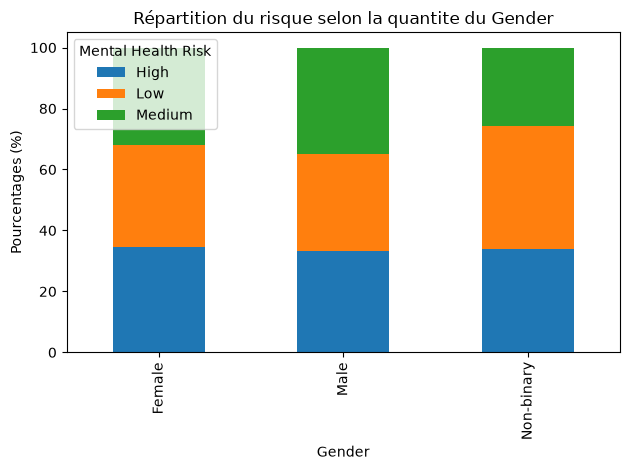

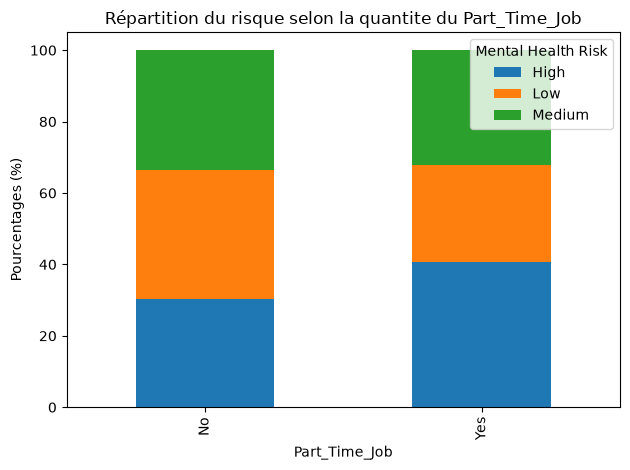

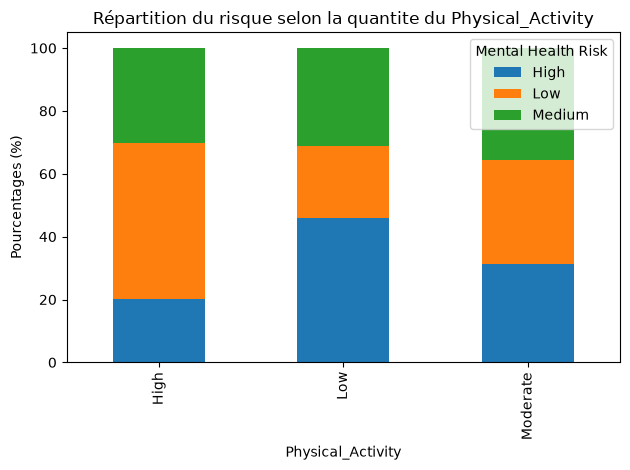

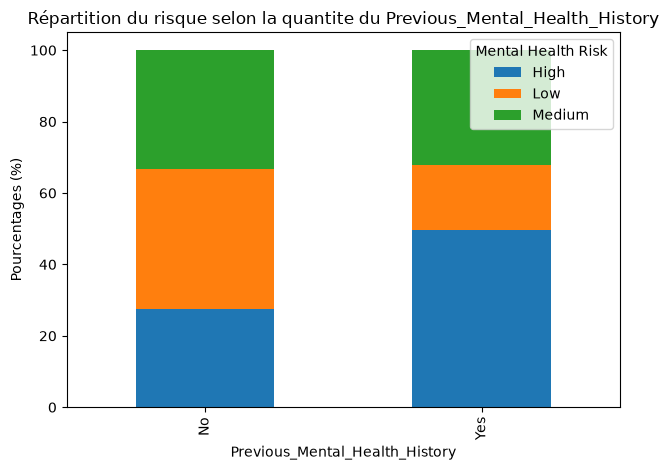

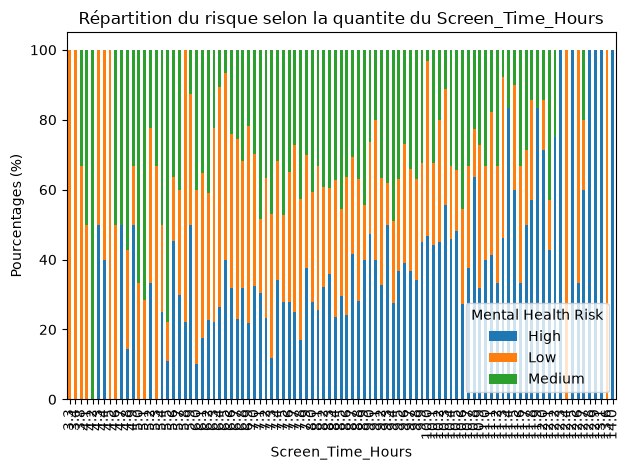

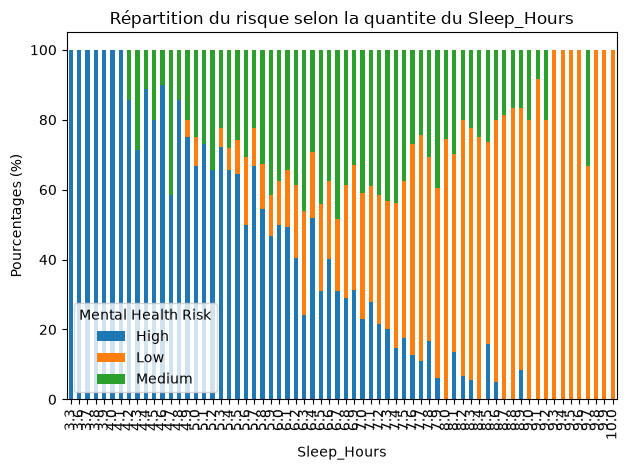

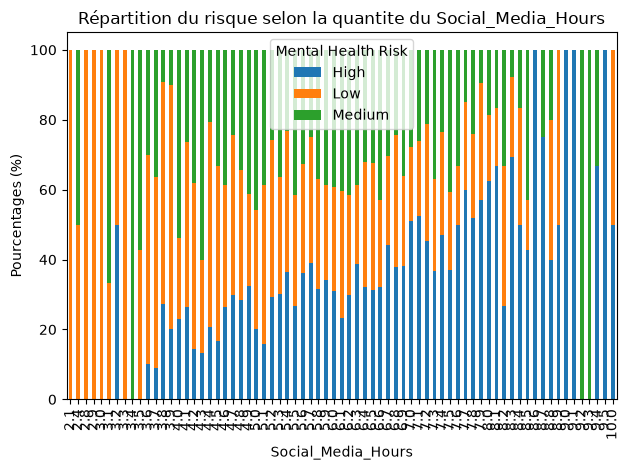

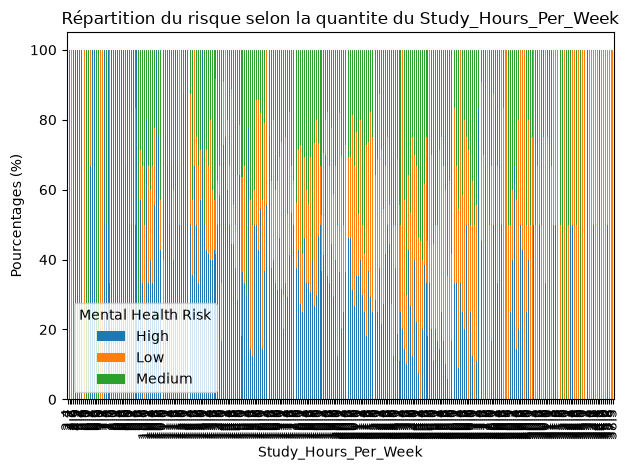

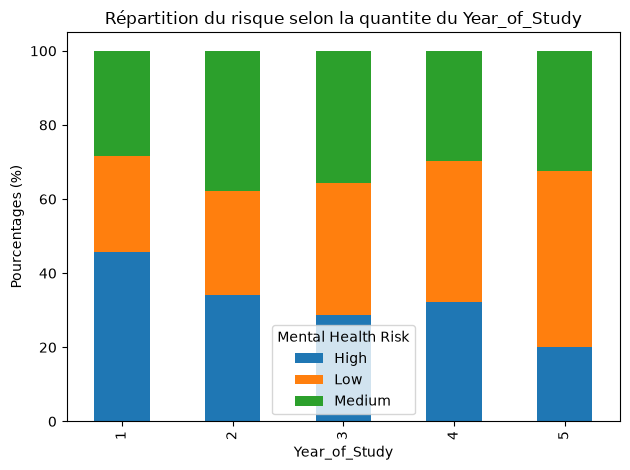

In [370]:
for col in df.columns.difference([target, 'Student_ID']):
      effectifs = pd.crosstab(df[col], df[target])
      portions = pd.crosstab(df[col], df[target], normalize='index').mul(100).round(2)

      portions.plot(kind='bar', stacked=True)
      plt.title(f'Répartition du risque selon la quantite du {col}')
      plt.xlabel(col)
      plt.ylabel("Pourcentages (%)")
      plt.legend(title="Mental Health Risk")
      plt.tight_layout()
      plt.show()


#### Étape 2 — Transformation et préparation des données

- Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).
- Traiter les valeurs manquantes en choisissant la méthode d’imputation la plus adaptée à la nature des données
- Détecter et traiter les valeurs aberrantes en utilisant une méthode appropriée (IQR, Z-score, etc.).
- Encoder les variables catégorielles afin de les convertir en valeurs numériques
- Gérer le déséquilibre des classes avec des techniques de sur-échantillonnage ou sous-échantillonnage (Smote), si nécessaire. 
- Normaliser ou standardiser les variables numériques afin de les mettre à la même échelle.
- Regrouper les transformations dans un pipeline afin d’éviter le data leakage. 
- Chaque décision de nettoyage doit être justifiée.

In [305]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [306]:
df_clean = df.copy()

In [307]:
df_clean = df_clean.drop(["Student_ID"], axis=1)

In [308]:
X = df_clean.drop(columns=['Mental_Health_Risk'])
y = df_clean['Mental_Health_Risk']

In [309]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1600, 15), (400, 15), (1600,), (400,))

In [ ]:
numerics_columns = X.select_dtypes(include='number').columns
numerics_columns
categorical_columns = X.select_dtypes(include=['object', 'category', 'string']).columns
categorical_columns
taile

Index(['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History'],
      dtype='str')

In [311]:
nominals_columns = [
      'Gender',
      'Part_Time_Job',
      'Previous_Mental_Health_History'
]

ordinals_columns = [
      'Physical_Activity',
      'Diet_Quality'
]
ordinals_columns
Physical_Activity_column = ['Physical_Activity']
Diet_Quality_column = ['Diet_Quality']
Physical_Activity_column, Diet_Quality_column

(['Physical_Activity'], ['Diet_Quality'])

In [312]:
from sklearn.base import BaseEstimator, TransformerMixin

class IQRClipper(BaseEstimator, TransformerMixin):
      def __init__(self, factor=1.5):
            self.factor = factor


      def fit(self, X, y=None):
            self.q1 = np.percentile(X, 25, axis=0)
            self.q3 = np.percentile(X, 75, axis=0)
            self.IQR = self.q3 - self.q1
            self.lower_bound_  = self.q1-(self.factor * self.IQR)
            self.upper_bound_ = self.q3 + (self.factor * self.IQR)
            return self

      def transform(self, X, y=None):
            X = np.asarray(X)
            X_clipped = np.clip(
                  X,
                  self.lower_bound_,
                  self.upper_bound_
            )

            return X_clipped


In [313]:
numerics_transformers = Pipeline(steps=[
      ('imputer', SimpleImputer(strategy='median')),
      ('iqr_clipper', IQRClipper()),
      ('scaler', StandardScaler(with_mean=False))
])

In [314]:
nominals_transformers = Pipeline(steps=[
      ('imputer', SimpleImputer(strategy='most_frequent')),
      ('on_hot_encoder', OneHotEncoder()),
])

In [315]:
Physical_Activity_transformers = Pipeline(steps=[
      ('imputer', SimpleImputer(strategy='most_frequent')),
      ('ordinal_encoder', OrdinalEncoder( categories=[['Low', 'Moderate', 'High']])),
])

In [316]:
Diet_Quality_transformers = Pipeline(steps=[
      ('imputer', SimpleImputer(strategy='most_frequent')),
      ('ordinal_encoder', OrdinalEncoder(categories=[['Poor', 'Average', 'Good']])),
])

In [317]:
features_preprocessor = ColumnTransformer([
      ('numerics', numerics_transformers, numerics_columns),
      ('nominals', nominals_transformers, nominals_columns),
      ('Physical_Activity', Physical_Activity_transformers, Physical_Activity_column),
      ('Diet_Quality', Diet_Quality_transformers, Diet_Quality_column)
      ],
      remainder='drop'
)

In [365]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
# import xgboost as xgb
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [347]:
models = {
      "LogisticRegression" : (LogisticRegression(max_iter=100, random_state=42), None),
      "DecisionTreeClassifier" : (DecisionTreeClassifier(max_depth=10, random_state=42), None),
      "RandomForestClassifier" : (RandomForestClassifier(n_estimators=10, max_depth=10, random_state=42), None),
      "SVC" : (SVC(kernel='linear'), None)
}

c:\Users\Youcode\Documents\DEVAI\Student_Mental_Health\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


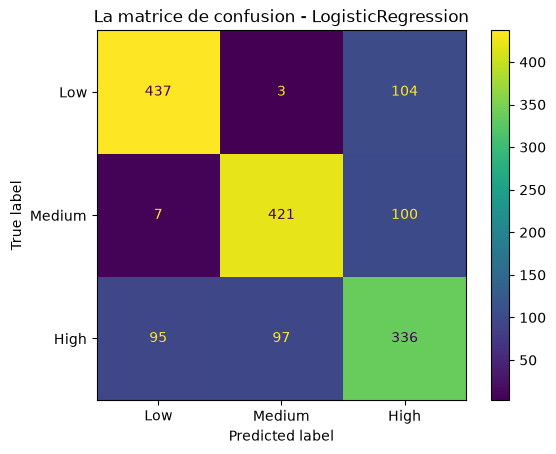

              precision    recall  f1-score   support

        High       0.81      0.80      0.81       544
         Low       0.81      0.80      0.80       528
      Medium       0.62      0.64      0.63       528

    accuracy                           0.75      1600
   macro avg       0.75      0.75      0.75      1600
weighted avg       0.75      0.75      0.75      1600



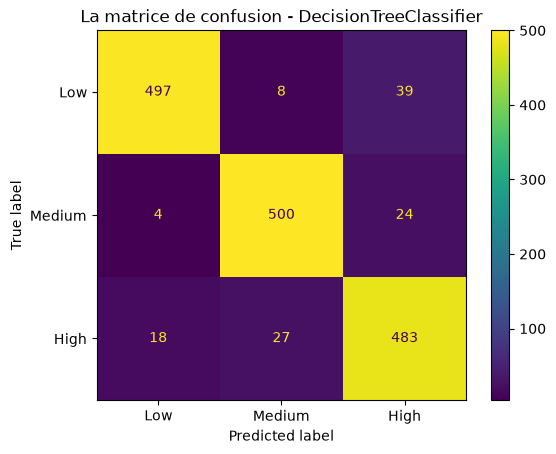

              precision    recall  f1-score   support

        High       0.96      0.91      0.94       544
         Low       0.93      0.95      0.94       528
      Medium       0.88      0.91      0.90       528

    accuracy                           0.93      1600
   macro avg       0.93      0.93      0.93      1600
weighted avg       0.93      0.93      0.93      1600



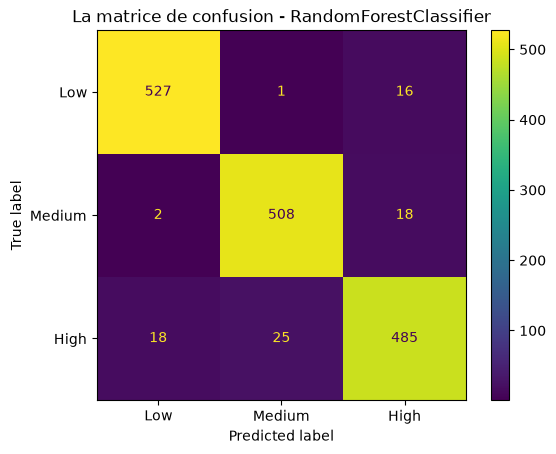

              precision    recall  f1-score   support

        High       0.96      0.97      0.97       544
         Low       0.95      0.96      0.96       528
      Medium       0.93      0.92      0.93       528

    accuracy                           0.95      1600
   macro avg       0.95      0.95      0.95      1600
weighted avg       0.95      0.95      0.95      1600



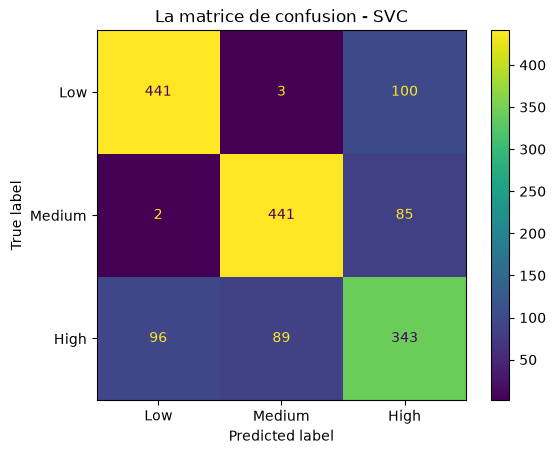

              precision    recall  f1-score   support

        High       0.82      0.81      0.81       544
         Low       0.83      0.84      0.83       528
      Medium       0.65      0.65      0.65       528

    accuracy                           0.77      1600
   macro avg       0.77      0.77      0.77      1600
weighted avg       0.77      0.77      0.77      1600

               model_name  accuracy_score  recall_score  f1_score
2  RandomForestClassifier        0.950000      0.949811  0.949743
1  DecisionTreeClassifier        0.925000      0.925115  0.925088
3                     SVC        0.765625      0.765170  0.765106
0      LogisticRegression        0.746250      0.745674  0.746300


In [367]:
results = []
for model_name, (model, params) in models.items():
      pipeline = Pipeline([
      ('preproces', features_preprocessor),
      ('classificator', model)
      ])
      pipeline.fit(X_train, y_train)
      # print(f"{model_name} : {pipeline.score(X_train, y_train)}")
      y_pred = pipeline.predict(X_train)
      results.append({
            "model_name" : model_name,
            "accuracy_score" : accuracy_score(y_train, y_pred),
            "recall_score" : recall_score(y_train, y_pred, average='macro'),
            "f1_score" : f1_score(y_train, y_pred, average='macro'),
      })
      cm = confusion_matrix(y_train, y_pred)
      ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["Low", "Medium", "High"])
      plt.title(f"La matrice de confusion - {model_name}")
      plt.show()

      print(classification_report(y_train, y_pred))

print(pd.DataFrame(results).sort_values(by='f1_score', ascending=False))